# Sieci Kohonena

In [1]:
import numpy as np
import pandas as pd
import math
from tqdm import tqdm
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import plotly.express as px
import matplotlib.patches as patches
from collections import Counter
import seaborn as sns

c:\Users\msado\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
def funkcja_wygaszajaca(t, wygaszanie):
    return np.exp(- t / wygaszanie)

def funkcja_Gaussa(d2_grid, sigma):
    return np.exp(-d2_grid / (2 * sigma**2))

def meksykanski_kapelusz(d2_grid, sigma):
    val = -d2_grid / (sigma**2)
    return (1 + val) * np.exp(val / 2)

In [3]:
class Kohonen:
    def __init__(self, M, N, len_wejscia, iteracje, sigma, funkcja_sasiedztwa, wygaszanie):
        self.M = M
        self.N = N
        self.len_wejscia = len_wejscia
        self.iteracje = iteracje
        self.sigma = sigma
        self.wagi = None
        self.funkcja_sasiedztwa = funkcja_sasiedztwa
        self.wygaszanie = wygaszanie
        self.min_vals = 0
        self.max_vals = 1

    def znajdz_najblizszy(self, x):
        # odległość euklidesowa
        odleglosci = np.linalg.norm(self.wagi - x, axis=-1)
        min_idx = np.argmin(odleglosci)
        return np.unravel_index(min_idx, (self.M, self.N))
    
    def update(self, x, best_coord, alpha):
        i_grid, j_grid = np.indices((self.M, self.N))
        d2_grid = (i_grid - best_coord[0])**2 + (j_grid - best_coord[1])**2
        theta = self.funkcja_sasiedztwa(d2_grid, self.sigma)
        theta = theta[..., np.newaxis]
        self.wagi += theta * alpha * (x - self.wagi)
        self.wagi = np.clip(self.wagi, self.min_vals, self.max_vals)

    def train(self, data):
        liczba_probek = data.shape[0]

        self.min_vals = np.min(data, axis=0) 
        self.max_vals = np.max(data, axis=0)
        self.wagi = np.random.uniform(self.min_vals, self.max_vals, (self.M, self.N, self.len_wejscia))

        for t in tqdm(range(self.iteracje)):
            alpha = funkcja_wygaszajaca(t, self.wygaszanie)

            indeksy = np.arange(liczba_probek)
            np.random.shuffle(indeksy)
          
            for idx in indeksy:
                x = data[idx] 
                best_coord = self.znajdz_najblizszy(x)
                self.update(x, best_coord, alpha)

In [4]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

In [5]:
def rysuj_wykres_2d(model, dane_2d, etykiety):
    fig, ax = plt.subplots(figsize=(8, 8))

    scatter = ax.scatter(dane_2d[:, 0], dane_2d[:, 1], 
                         c=etykiety.flatten(), cmap='tab10', 
                         alpha=0.4)

    legend_klasy = ax.legend(*scatter.legend_elements(), title="Prawdziwe Klasy", loc="upper right")
    ax.add_artist(legend_klasy)

    wx = model.wagi[:, :, 0]
    wy = model.wagi[:, :, 1]

    ax.scatter(wx.flatten(), wy.flatten(), c='red', marker='o', s=80, label='Neurony', zorder=5, edgecolors='black')

    for i in range(model.M):
        ax.plot(wx[i, :], wy[i, :], c='black', alpha=0.6, linewidth=1.5)
        
    for j in range(model.N):
        ax.plot(wx[:, j], wy[:, j], c='black', alpha=0.6, linewidth=1.5)

    ax.set_title('Dopasowanie Siatki Kohonena')
    
    ax.legend(loc="upper left")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

In [6]:
def wykres_3d(model, data, etykiety):
    fig = go.Figure()

    etykiety_plaskie = etykiety.flatten()
    unikalne_klasy = np.unique(etykiety_plaskie)
    
    kolory = px.colors.qualitative.D3 

    for i, klasa in enumerate(unikalne_klasy):
        idx = (etykiety_plaskie == klasa)
        fig.add_trace(go.Scatter3d(
            x=data[idx, 0], 
            y=data[idx, 1], 
            z=data[idx, 2],
            mode='markers',
            marker=dict(
                size=3,
                color=kolory[i % len(kolory)], 
                opacity=0.3
            ),
            name=f'Klasa {klasa}' 
        ))

    wx = model.wagi[:, :, 0]
    wy = model.wagi[:, :, 1]
    wz = model.wagi[:, :, 2]

    fig.add_trace(go.Scatter3d(
        x=wx.flatten(), 
        y=wy.flatten(), 
        z=wz.flatten(),
        mode='markers',
        marker=dict(
            size=5, 
            color='red', 
            line=dict(color='black', width=2) 
        ),
        name='Neurony'
    ))

    for i in range(model.M):
        fig.add_trace(go.Scatter3d(
            x=wx[i, :], y=wy[i, :], z=wz[i, :],
            mode='lines',
            line=dict(color='black', width=2),
            showlegend=False, 
            opacity=0.6
        ))
        
    for j in range(model.N):
        fig.add_trace(go.Scatter3d(
            x=wx[:, j], y=wy[:, j], z=wz[:, j],
            mode='lines',
            line=dict(color='black', width=2),
            showlegend=False,
            opacity=0.6
        ))

    fig.update_layout(
        title='Dopasowanie Siatki Kohonena',
        margin=dict(l=0, r=0, b=0, t=40),
        legend_title_text='Legenda'
    )

    fig.show()

In [7]:
def mapping_plot(model, dane, etykiety):
    fig, ax = plt.subplots(figsize=(10, 10))
    
    neurony_klasy = {(i, j): [] for i in range(model.M) for j in range(model.N)}
    
    etykiety_plaskie = etykiety.flatten()
    for idx, x in enumerate(dane):
        bmu_coord = model.znajdz_najblizszy(x)
        klasa = etykiety_plaskie[idx]
        neurony_klasy[bmu_coord].append(klasa)
        
    cmap = plt.get_cmap('tab10')
    
    poprawne_trafienia = 0
    wszystkie_probki = len(dane)
    
    for i in range(model.M):
        for j in range(model.N):
            klasy_w_neuronie = neurony_klasy[(i, j)]
            liczba_punktow = len(klasy_w_neuronie)
            
            if liczba_punktow > 0:
                licznik = Counter(klasy_w_neuronie)
                dominujaca_klasa, liczba_w_dominujacej = licznik.most_common(1)[0]
                
                poprawne_trafienia += liczba_w_dominujacej
                
                kolor_tla = cmap(dominujaca_klasa)
                alpha_tla = 0.3
            else:
                kolor_tla = 'white'
                alpha_tla = 1.0
                
            rect = patches.Rectangle((i - 0.5, j - 0.5), 1, 1, 
                                     linewidth=1, edgecolor='black', 
                                     facecolor=kolor_tla, alpha=alpha_tla)
            ax.add_patch(rect)
            
            if liczba_punktow > 0:
                jitter_x = np.random.uniform(-0.35, 0.35, liczba_punktow)
                jitter_y = np.random.uniform(-0.35, 0.35, liczba_punktow)
                
                px = i + jitter_x
                py = j + jitter_y
                
                kolory_kropek = [cmap(k) for k in klasy_w_neuronie]
                ax.scatter(px, py, c=kolory_kropek, edgecolors='black', s=30, zorder=5)

    accuracy = poprawne_trafienia / wszystkie_probki
    procent_accuracy = accuracy * 100
    
    ax.set_xlim(-0.5, model.M - 0.5)
    ax.set_ylim(-0.5, model.N - 0.5)
    ax.set_aspect('equal') 
    ax.set_xticks(range(model.M))
    ax.set_yticks(range(model.N))
    
    ax.set_title(f'Mapping plot\nAccuracy: {procent_accuracy:.2f}%', fontsize=14, fontweight='bold')
    
    plt.grid(False) 
    plt.show()
    
    return accuracy

# Dane hexagon

In [8]:
hexagon = pd.read_csv("mio2/hexagon.csv")

hexagon_data = hexagon[['x', 'y']].to_numpy() 
y_etykiety = hexagon[['c']].to_numpy().astype(int) 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = hexagon_data.shape[1]

In [9]:
model = Kohonen(4, 4, n, 100, 0.2, funkcja_Gaussa, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:01<00:00, 51.26it/s]


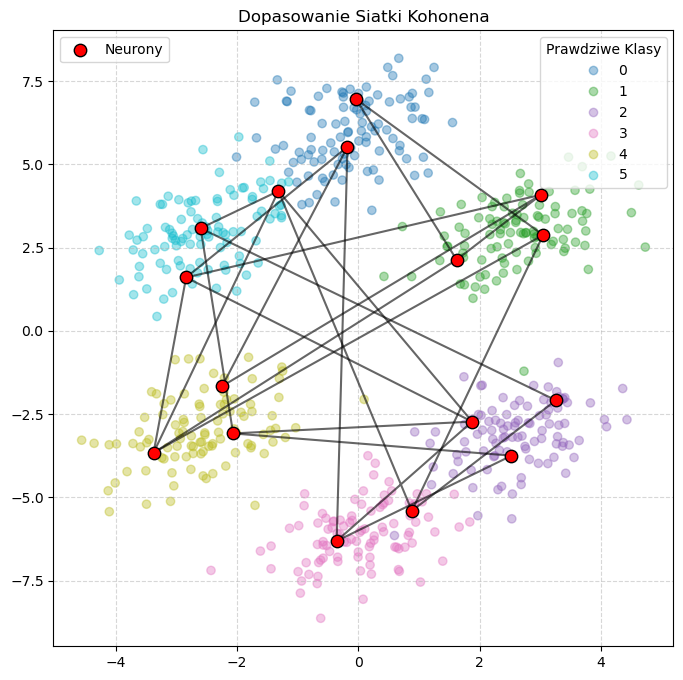

In [10]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

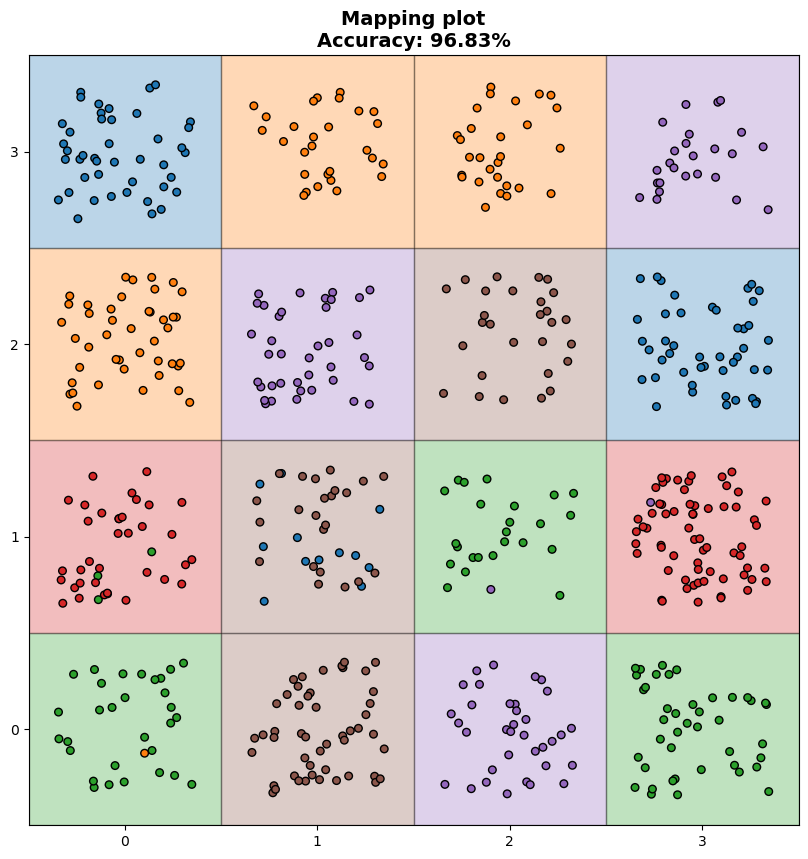

In [11]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [12]:
model = Kohonen(6, 6, n, 100, 0.2, funkcja_Gaussa, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 49.38it/s]


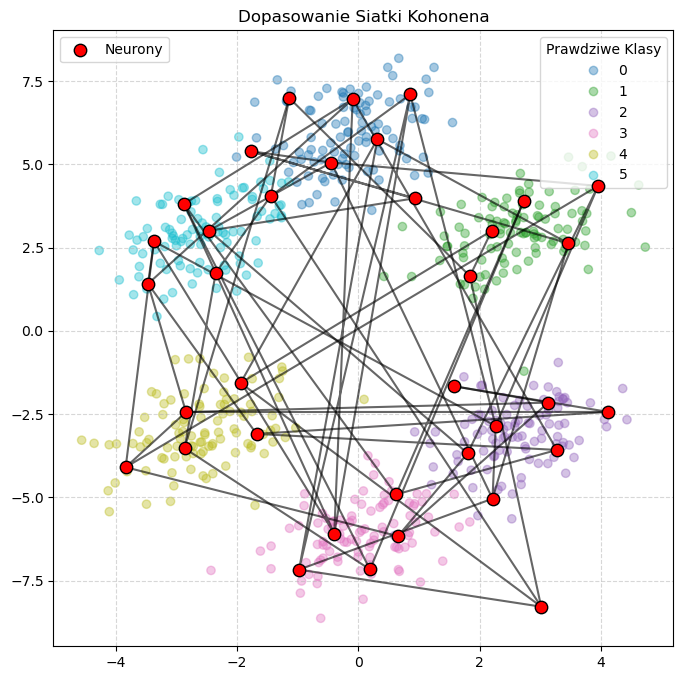

In [13]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

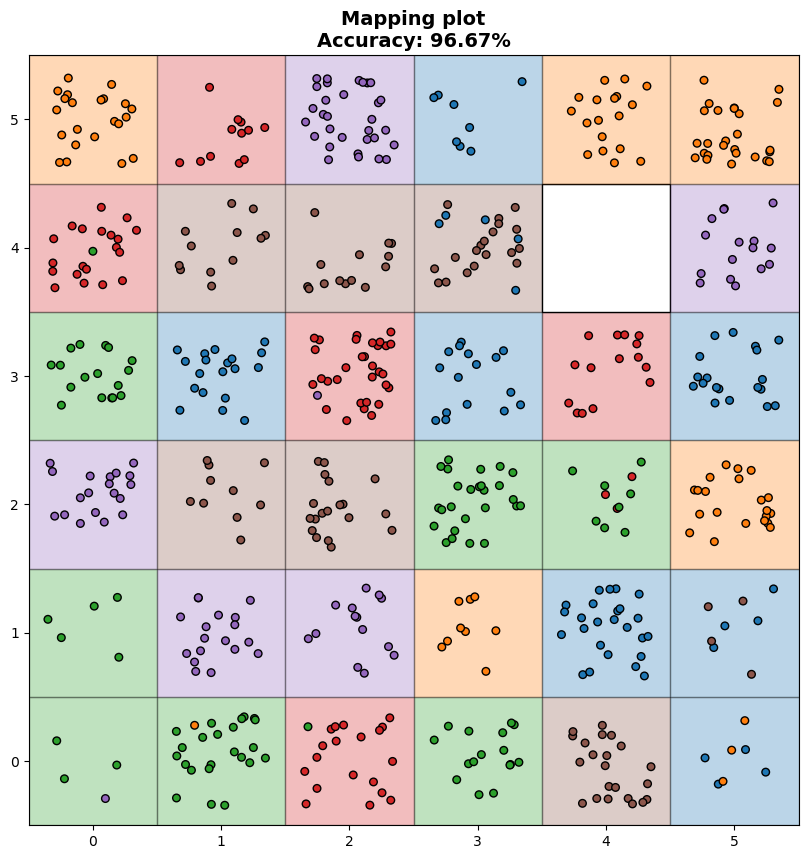

In [14]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [15]:
model = Kohonen(10, 10, n, 100, 0.2, funkcja_Gaussa, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 43.18it/s]


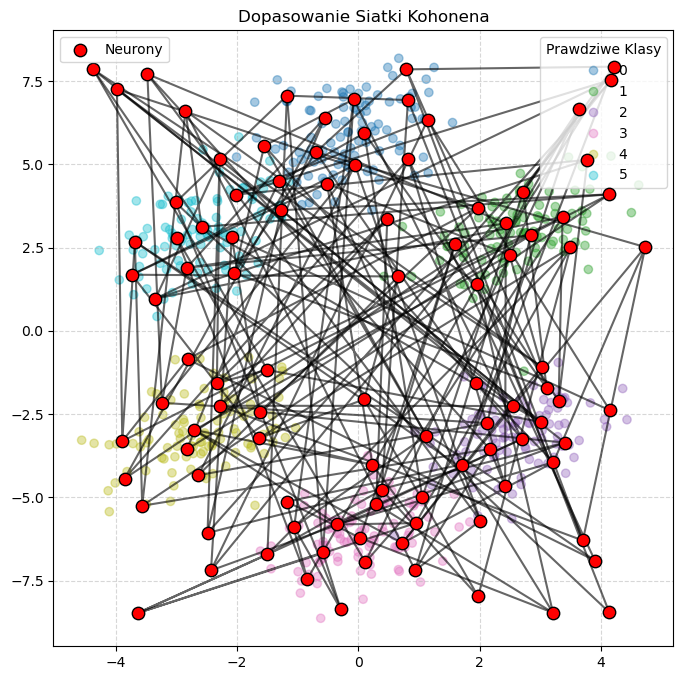

In [16]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

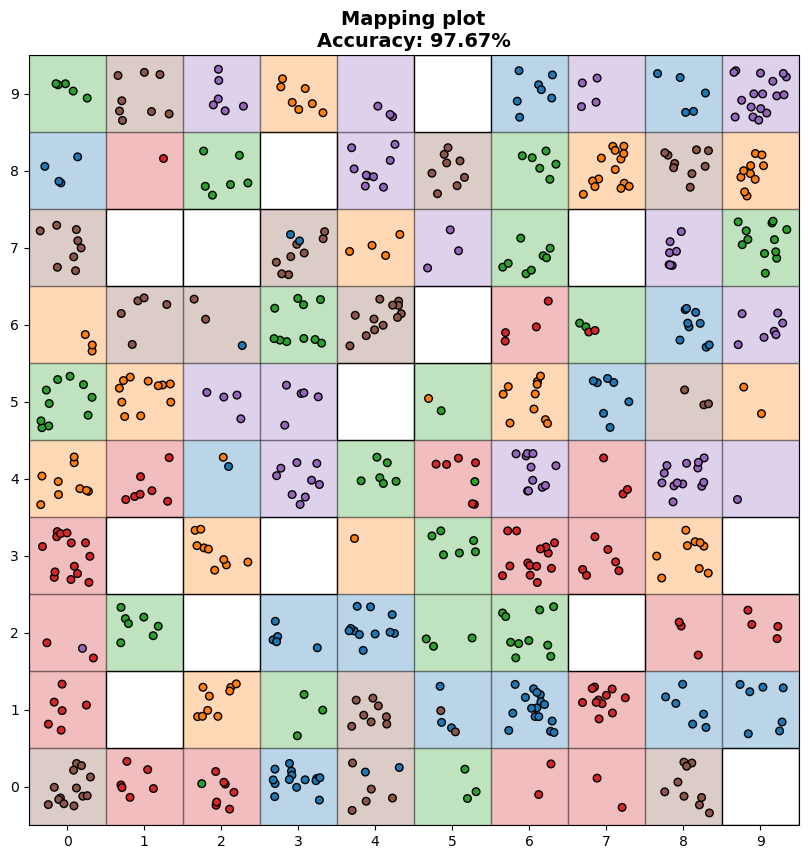

In [17]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [18]:
model = Kohonen(4, 4, n, 100, 0.5, funkcja_Gaussa, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 49.79it/s]


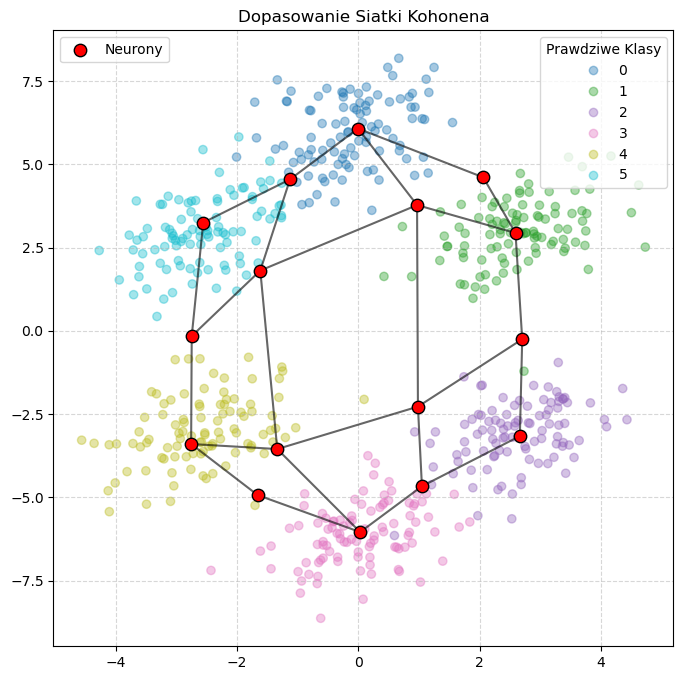

In [19]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

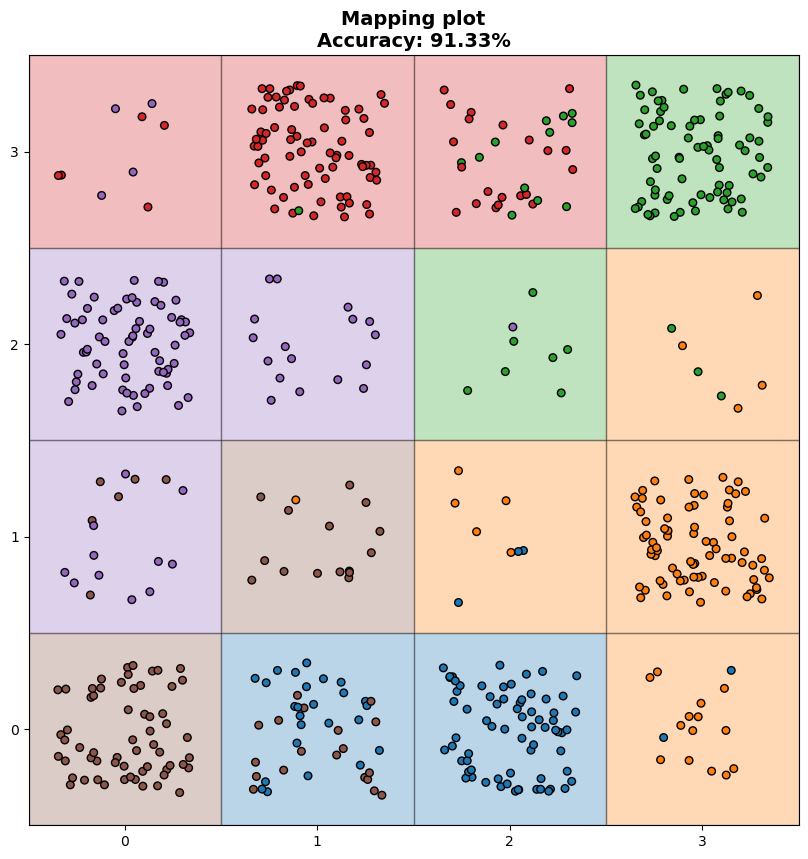

In [20]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [21]:
model = Kohonen(6, 6, n, 100, 0.5, funkcja_Gaussa, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 48.82it/s]


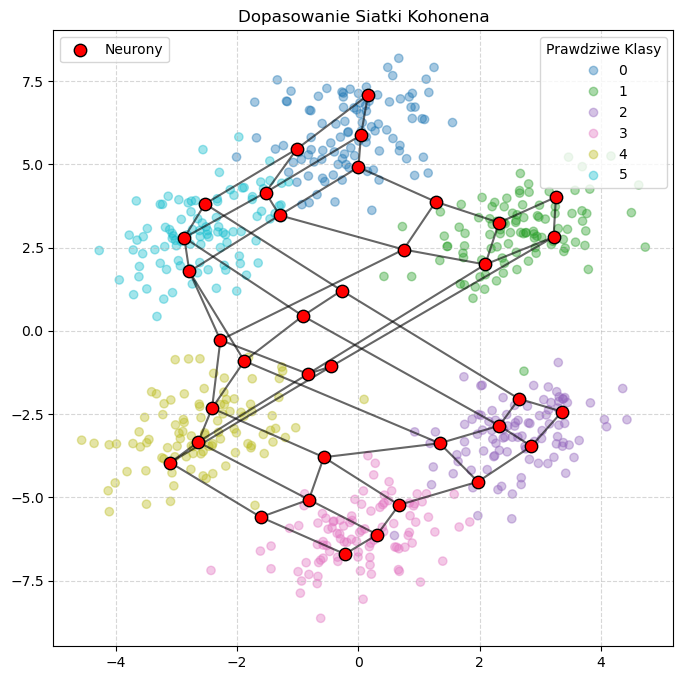

In [22]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

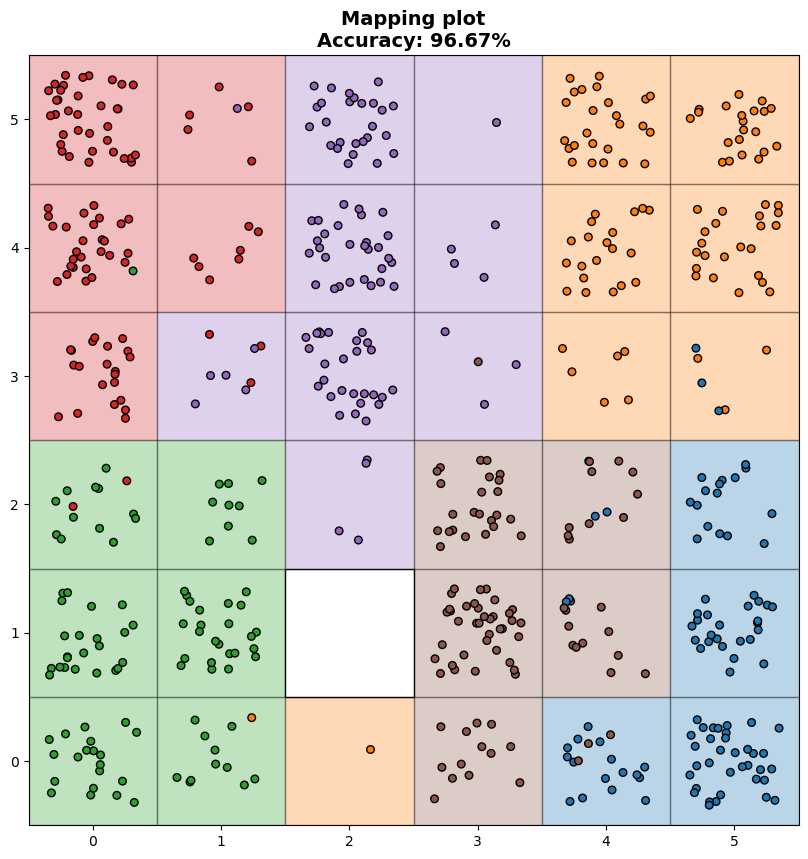

In [23]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [24]:
model = Kohonen(6, 6, n, 100, 1, funkcja_Gaussa, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 49.66it/s]


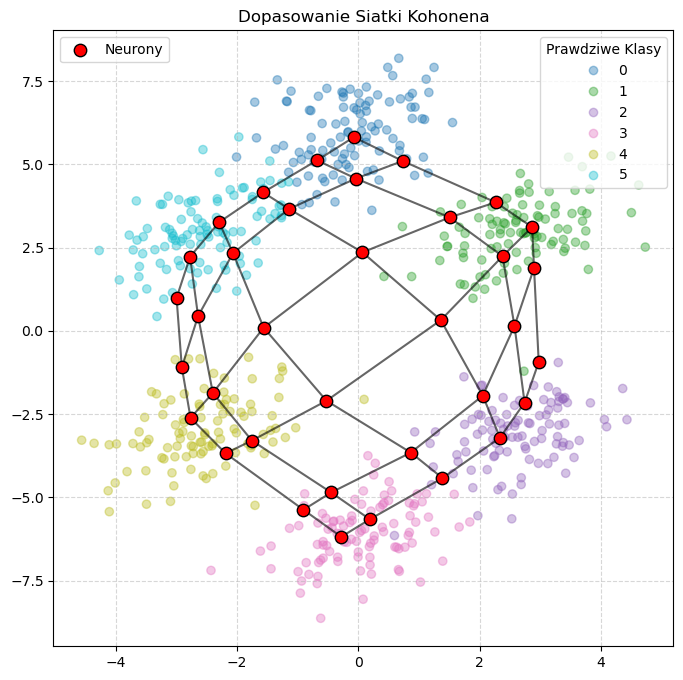

In [25]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

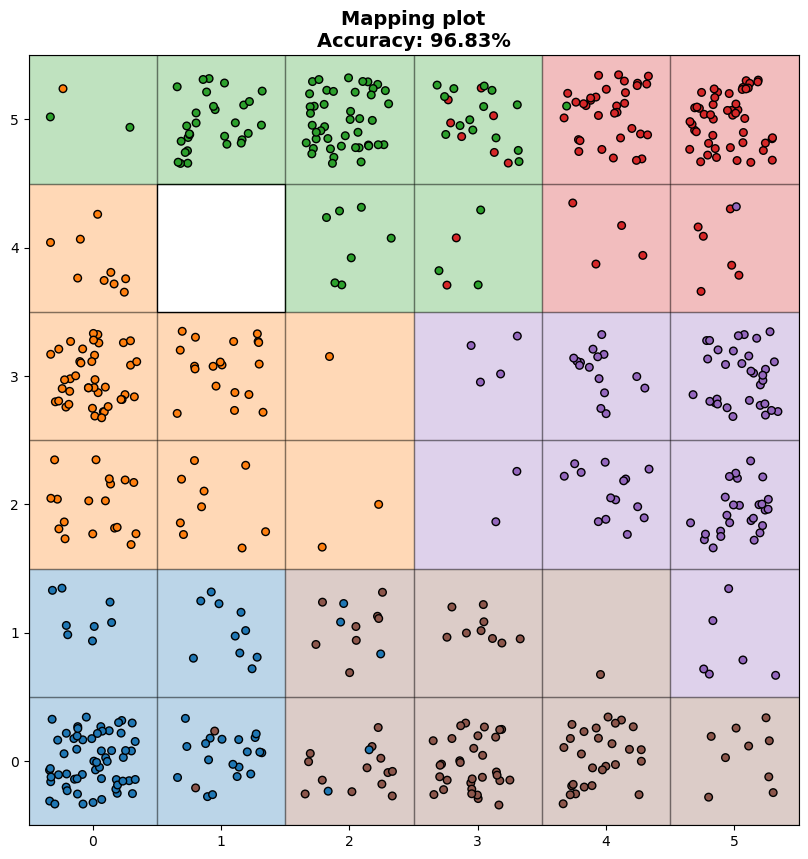

In [26]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [27]:
model = Kohonen(4, 4, n, 100, 0.2, meksykanski_kapelusz, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 46.41it/s]


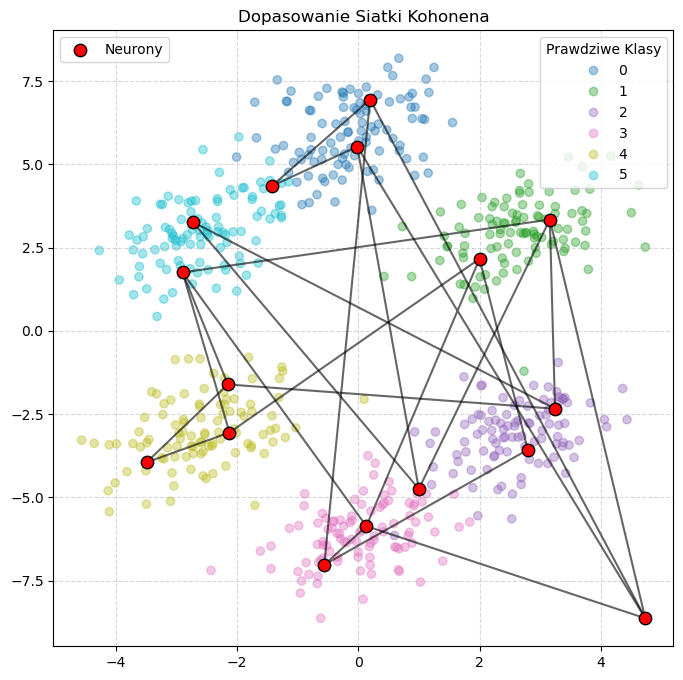

In [28]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

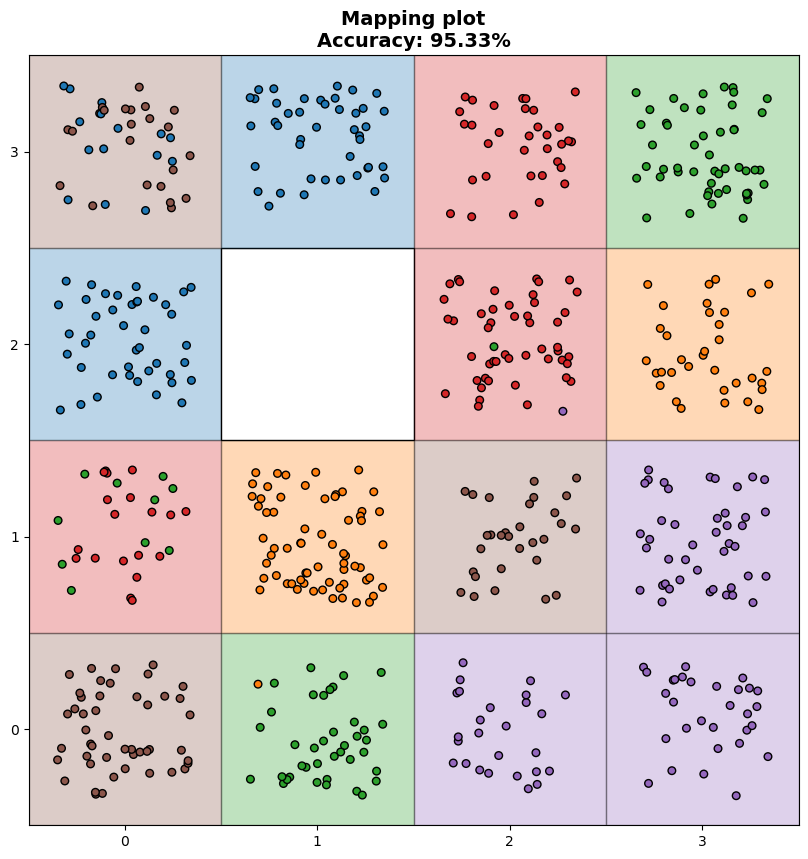

In [29]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [30]:
model = Kohonen(6, 6, n, 100, 0.2, meksykanski_kapelusz, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 46.31it/s]


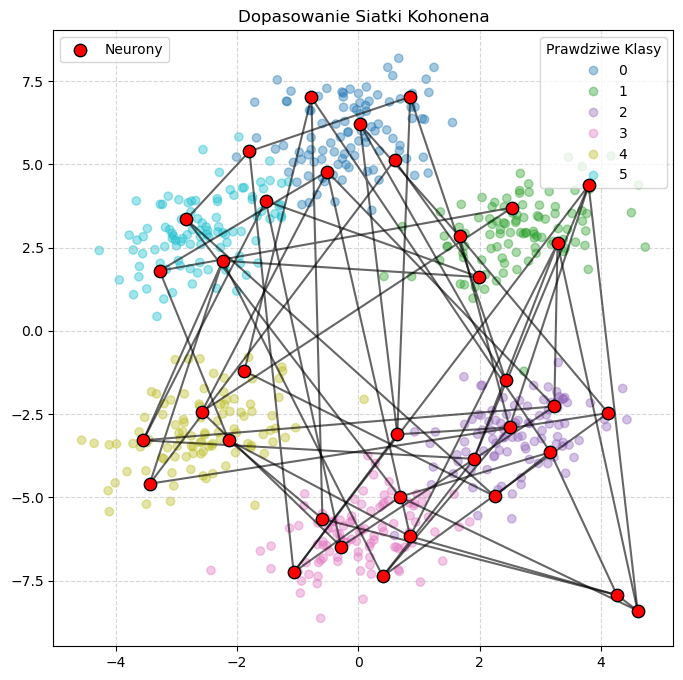

In [31]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

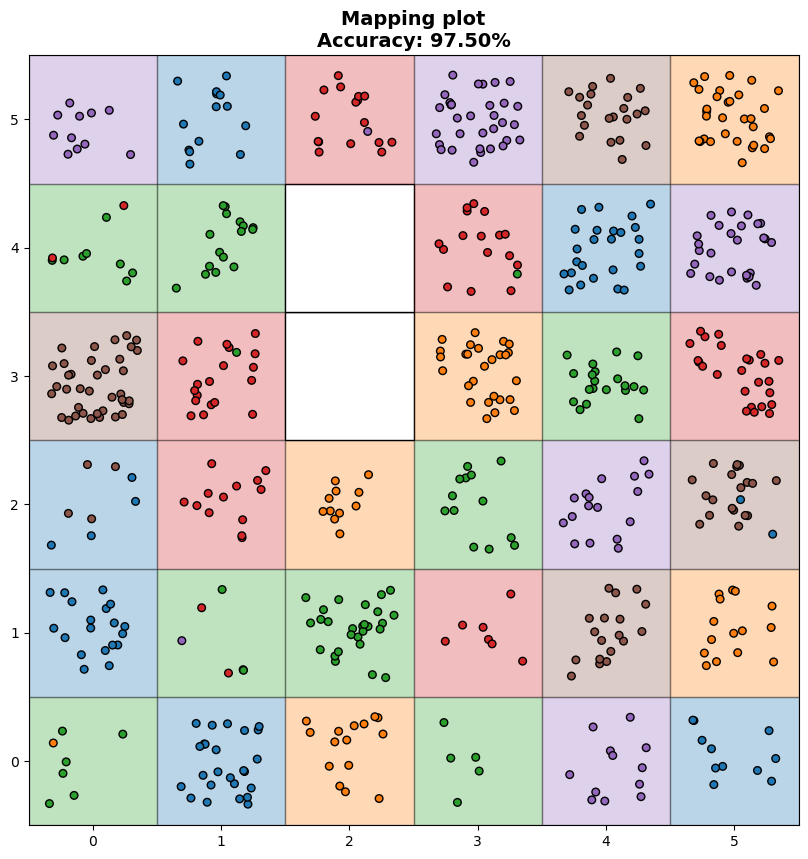

In [32]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [33]:
model = Kohonen(10, 10, n, 100, 0.2, meksykanski_kapelusz, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 40.72it/s]


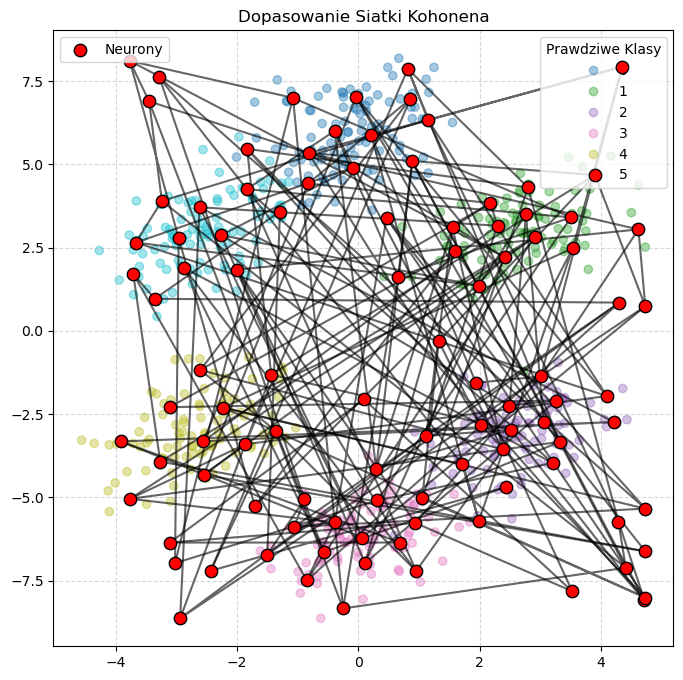

In [34]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

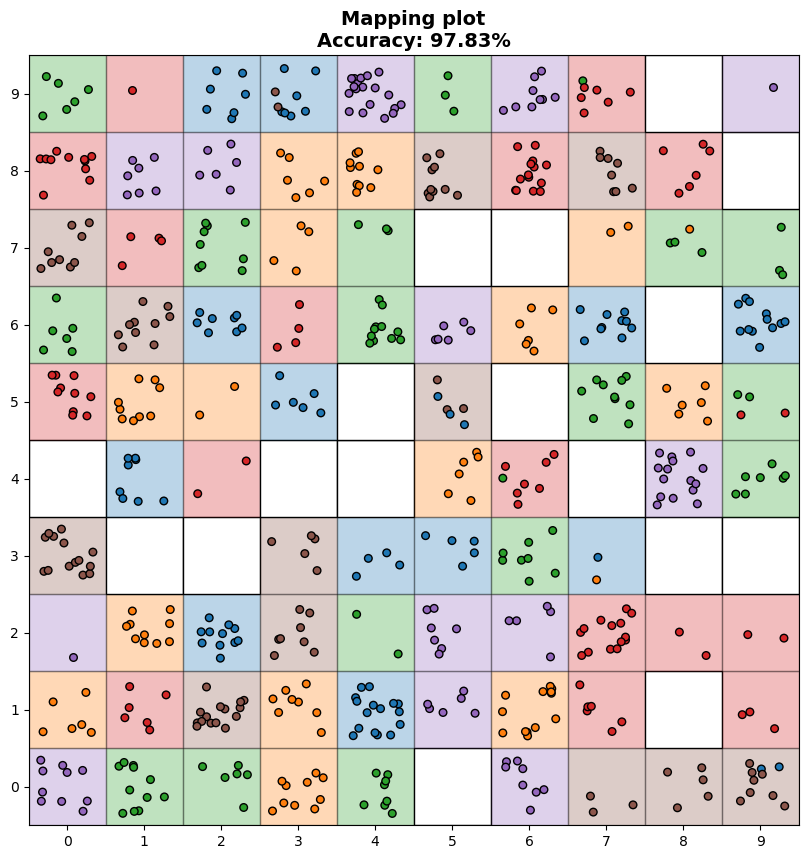

In [35]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [36]:
model = Kohonen(4, 4, n, 100, 1, meksykanski_kapelusz, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 47.10it/s]


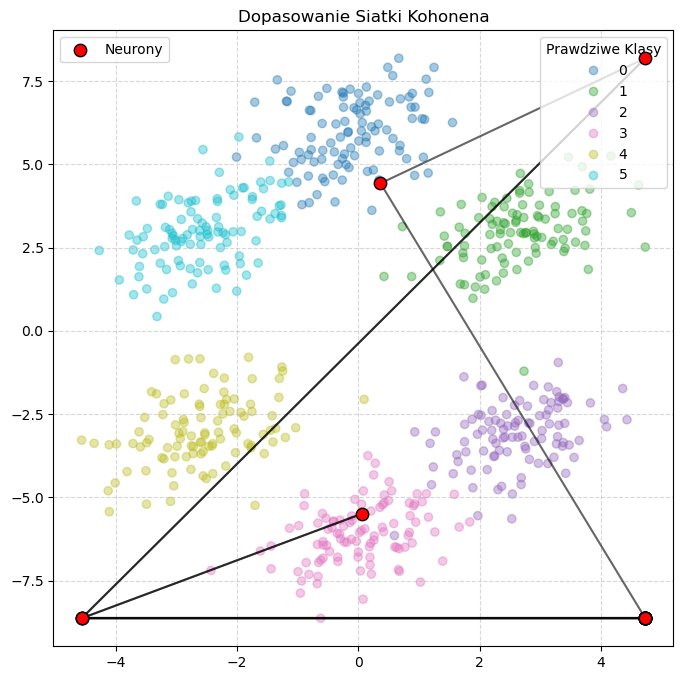

In [37]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

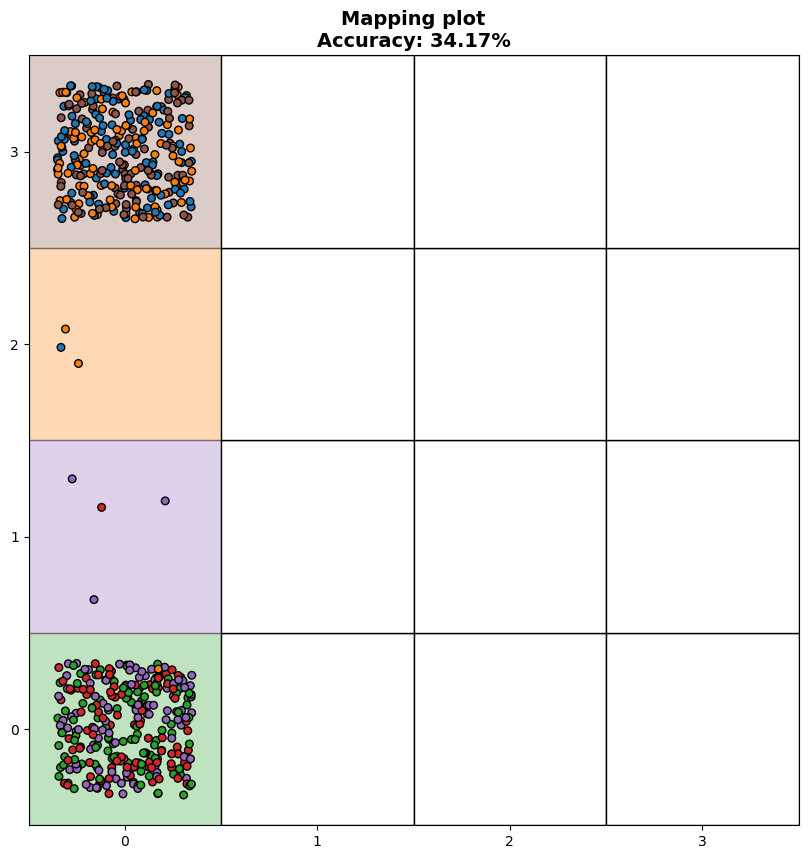

In [38]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [39]:
model = Kohonen(6, 6, n, 100, 1, meksykanski_kapelusz, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 45.43it/s]


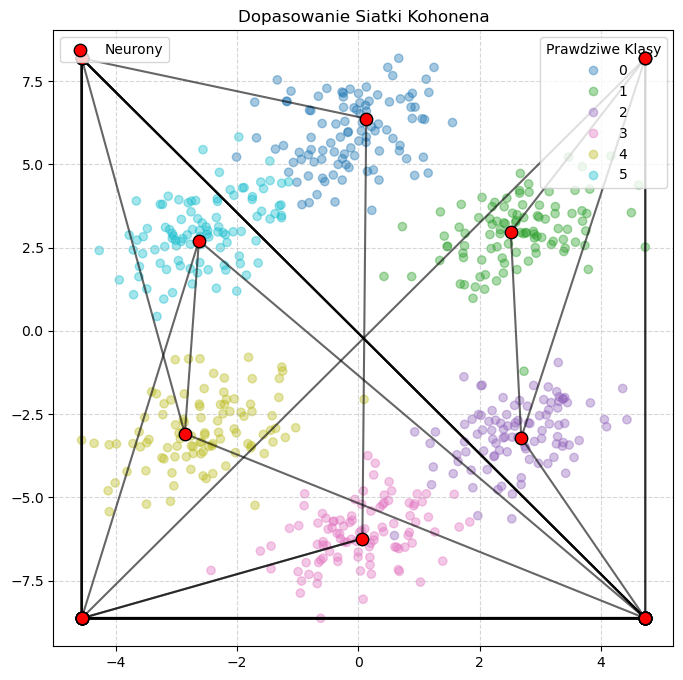

In [40]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

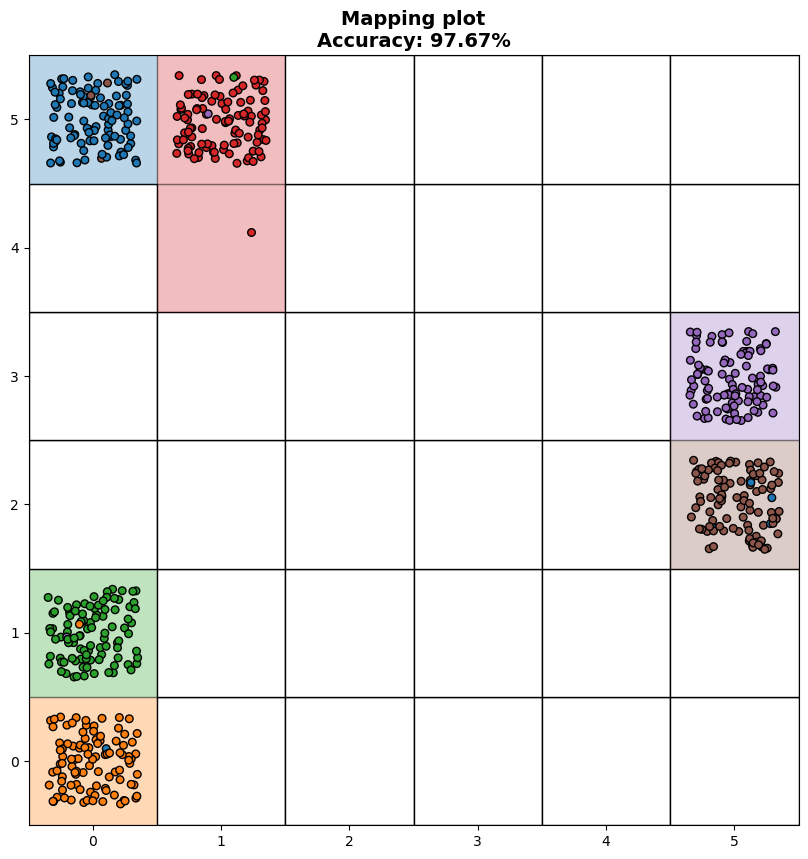

In [41]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

In [42]:
model = Kohonen(10, 10, n, 100, 1, meksykanski_kapelusz, 50)
model.train(hexagon_data)

100%|██████████| 100/100 [00:02<00:00, 41.77it/s]


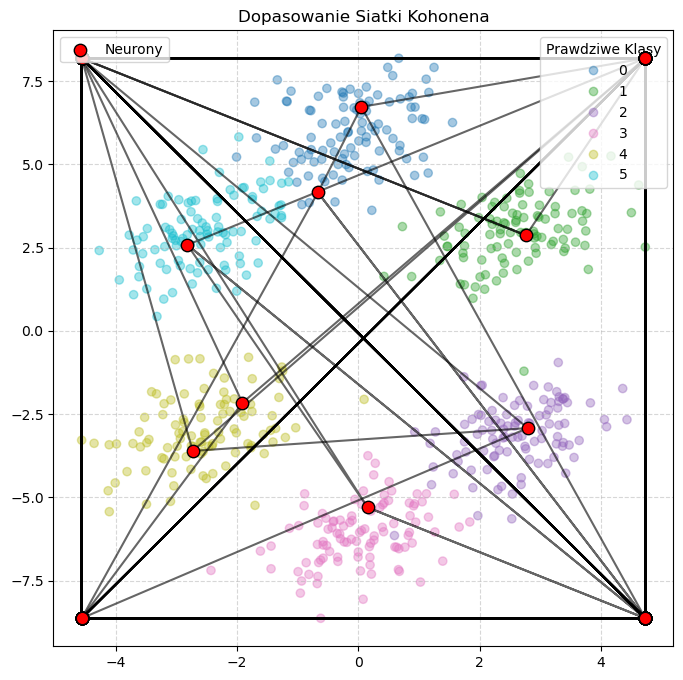

In [43]:
rysuj_wykres_2d(model, hexagon_data, y_etykiety)

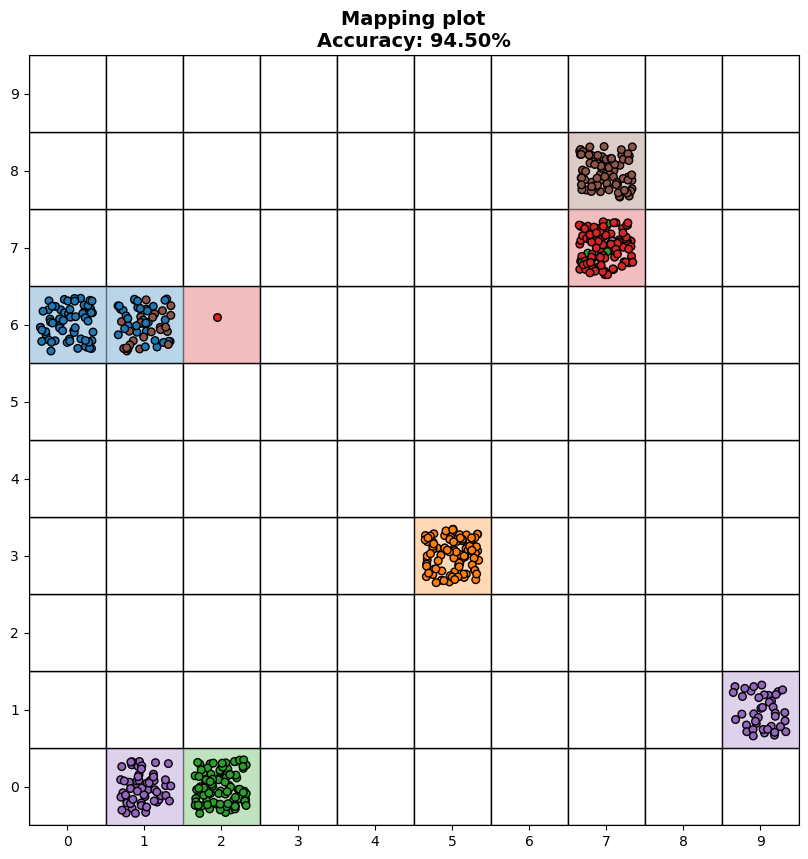

In [44]:
accuracy = mapping_plot(model, hexagon_data, y_etykiety)

# Dane cube

In [8]:
cube = pd.read_csv("mio2/cube.csv")

cube_data = cube[['x', 'y', 'z']].to_numpy() 
y_etykiety = cube[['c']].to_numpy().astype(int) 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = cube_data.shape[1]

In [9]:
model = Kohonen(4, 4, n, 100, 0.2, funkcja_Gaussa, 50)
model.train(cube_data)

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:04<00:00, 24.01it/s]


In [10]:
wykres_3d(model, cube_data, y_etykiety)

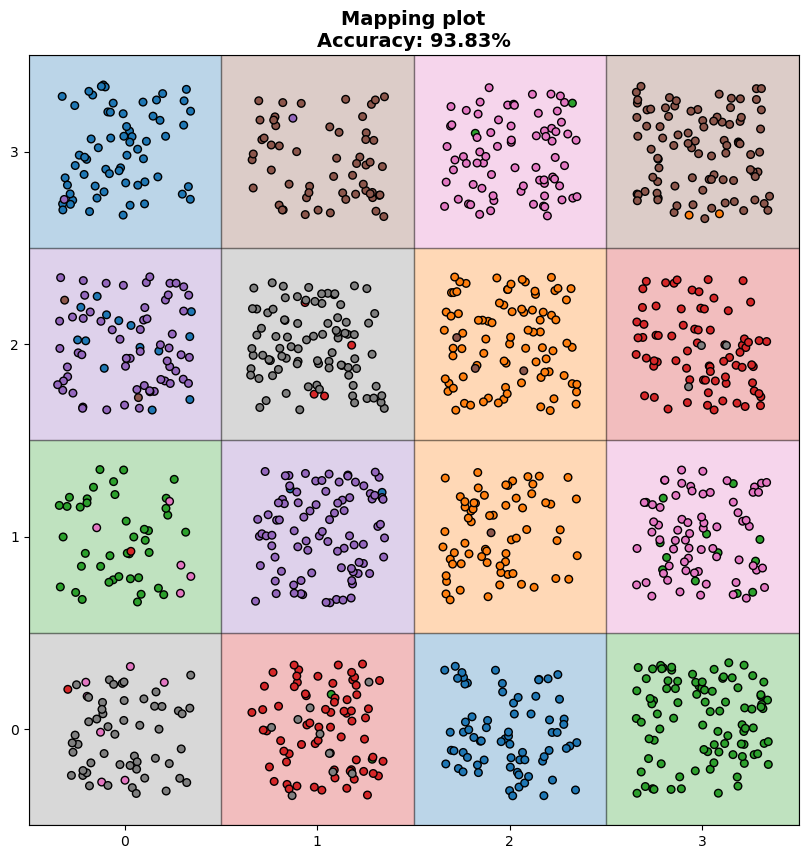

In [11]:
accuracy = mapping_plot(model, cube_data, y_etykiety)

In [12]:
model = Kohonen(6, 6, n, 100, 0.2, funkcja_Gaussa, 50)
model.train(cube_data)

100%|██████████| 100/100 [00:04<00:00, 23.24it/s]


In [13]:
wykres_3d(model, cube_data, y_etykiety)

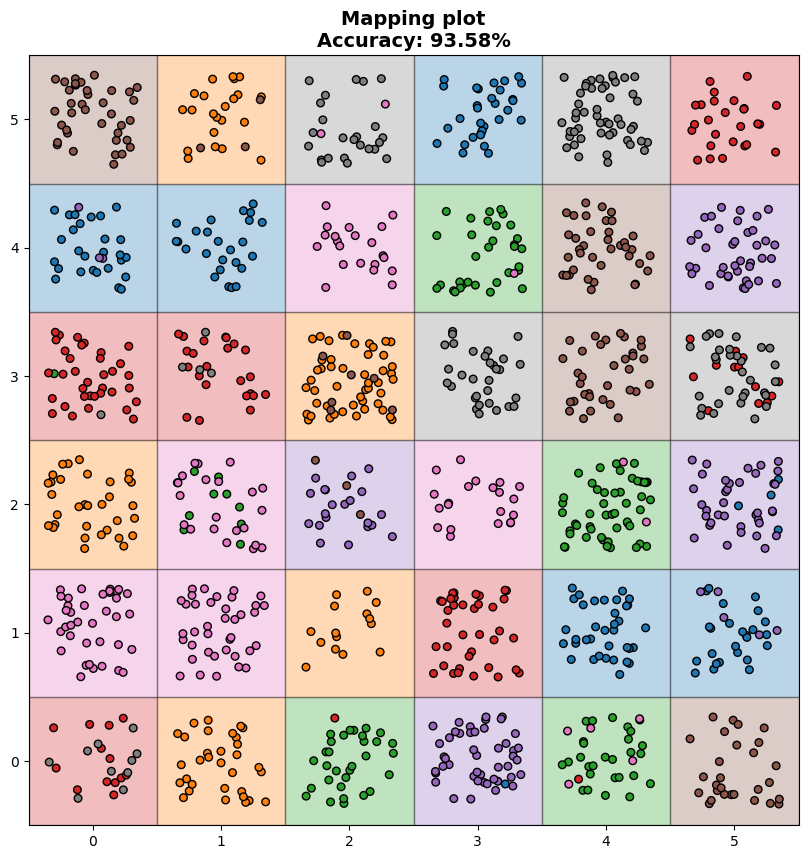

In [14]:
accuracy = mapping_plot(model, cube_data, y_etykiety)

In [15]:
model = Kohonen(10, 10, n, 100, 0.2, funkcja_Gaussa, 50)
model.train(cube_data)

100%|██████████| 100/100 [00:04<00:00, 21.22it/s]


In [16]:
wykres_3d(model, cube_data, y_etykiety)

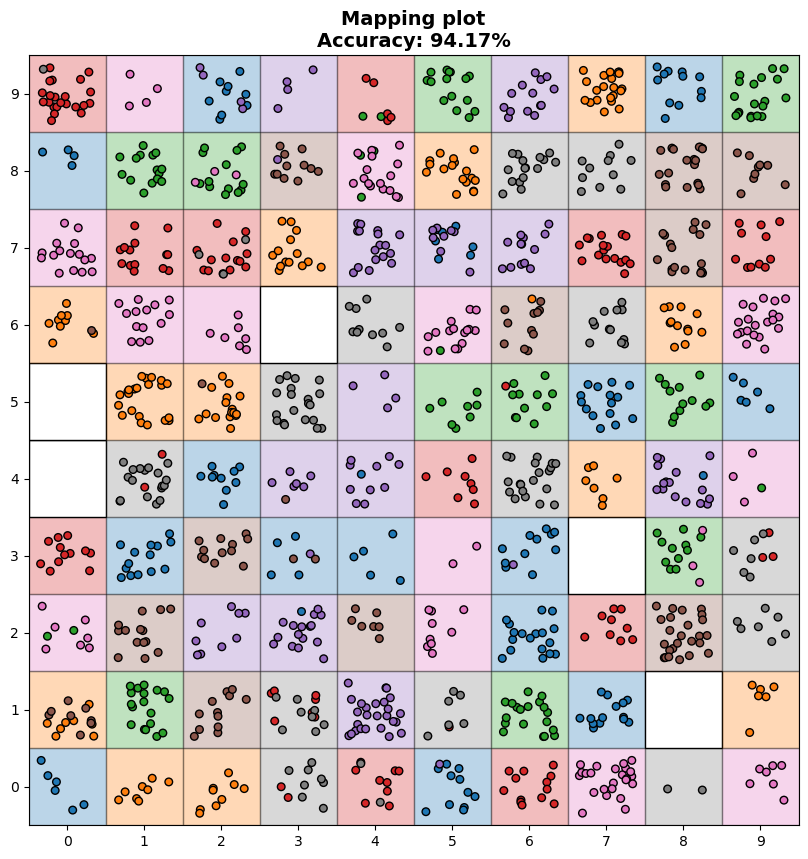

In [17]:
accuracy = mapping_plot(model, cube_data, y_etykiety)

In [18]:
model = Kohonen(4, 4, n, 100, 1, funkcja_Gaussa, 50)
model.train(cube_data)

100%|██████████| 100/100 [00:04<00:00, 23.12it/s]


In [19]:
wykres_3d(model, cube_data, y_etykiety)

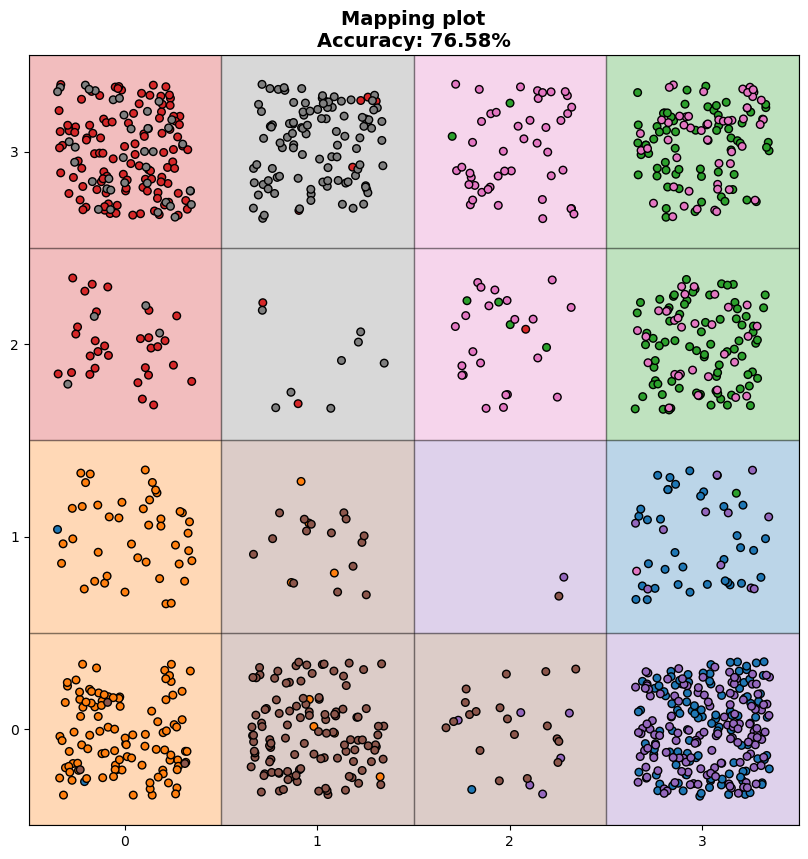

In [20]:
accuracy = mapping_plot(model, cube_data, y_etykiety)

In [21]:
model = Kohonen(6, 6, n, 100, 1, funkcja_Gaussa, 50)
model.train(cube_data)

100%|██████████| 100/100 [00:04<00:00, 23.07it/s]


In [22]:
wykres_3d(model, cube_data, y_etykiety)

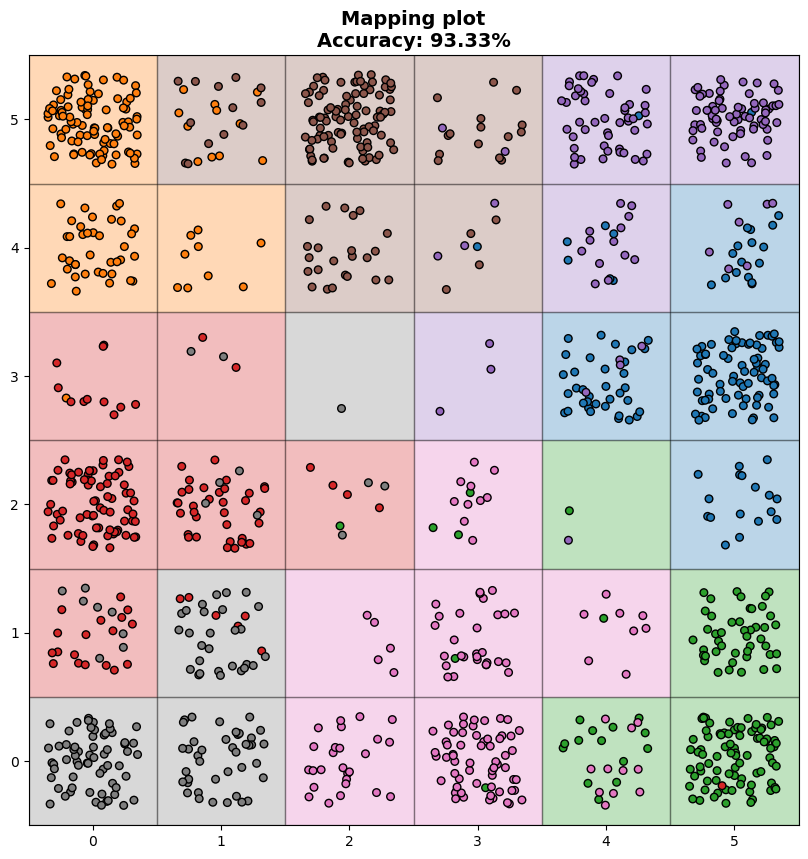

In [23]:
accuracy = mapping_plot(model, cube_data, y_etykiety)

In [24]:
model = Kohonen(10, 10, n, 100, 1, funkcja_Gaussa, 50)
model.train(cube_data)

100%|██████████| 100/100 [00:04<00:00, 21.13it/s]


In [25]:
wykres_3d(model, cube_data, y_etykiety)

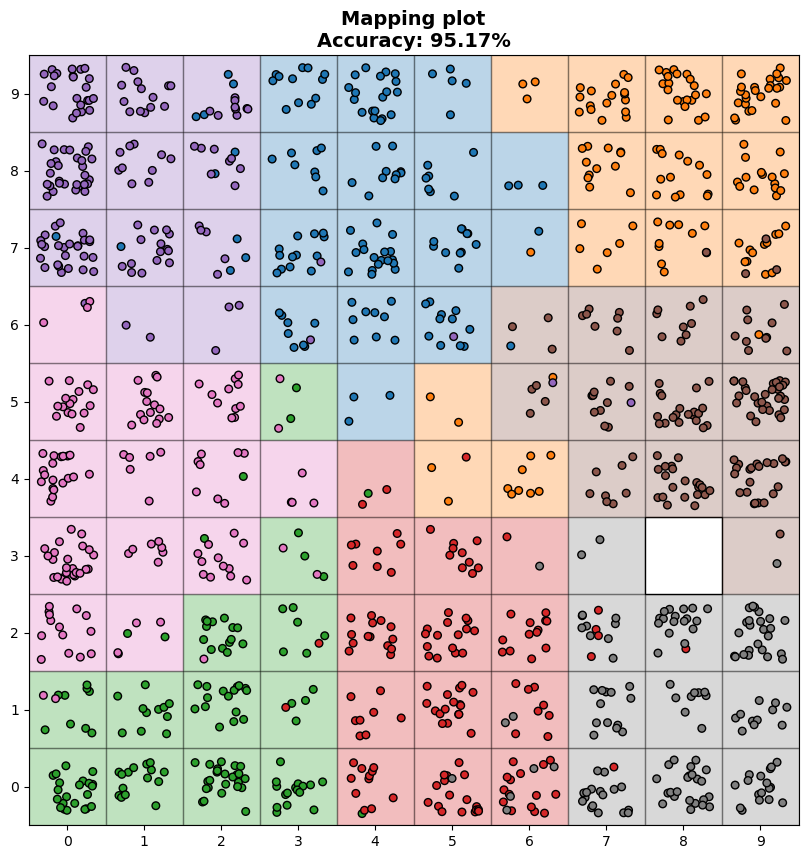

In [26]:
accuracy = mapping_plot(model, cube_data, y_etykiety)

In [27]:
model = Kohonen(4, 4, n, 100, 1, meksykanski_kapelusz, 50)
model.train(cube_data)

100%|██████████| 100/100 [00:04<00:00, 24.19it/s]


In [28]:
wykres_3d(model, cube_data, y_etykiety)

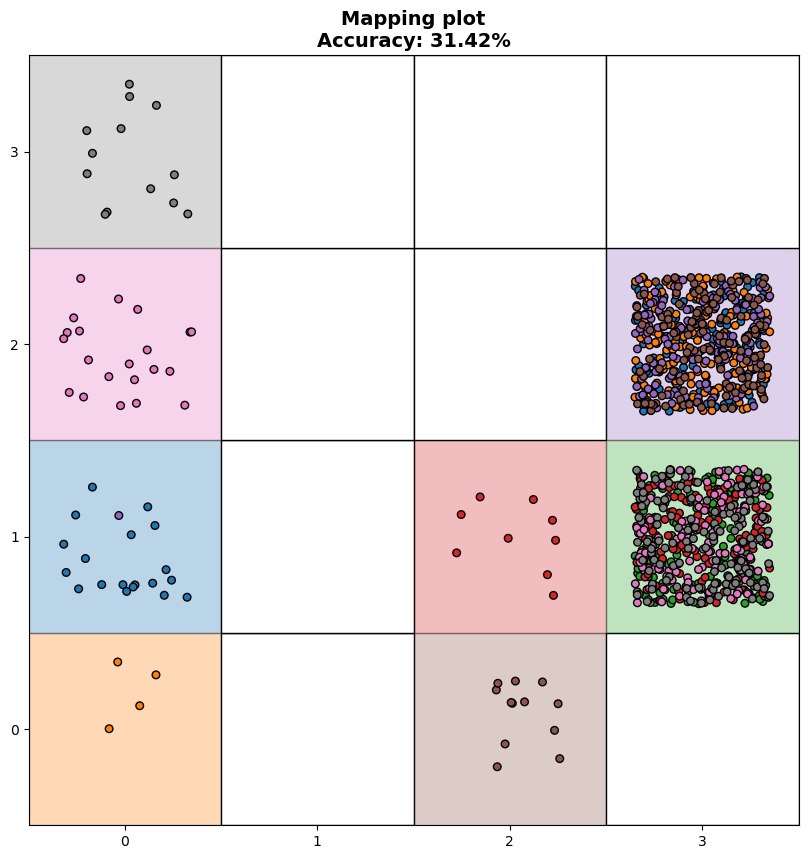

In [29]:
accuracy = mapping_plot(model, cube_data, y_etykiety)

In [30]:
model = Kohonen(6, 6, n, 100, 1, meksykanski_kapelusz, 50)
model.train(cube_data)

100%|██████████| 100/100 [00:04<00:00, 23.80it/s]


In [31]:
wykres_3d(model, cube_data, y_etykiety)

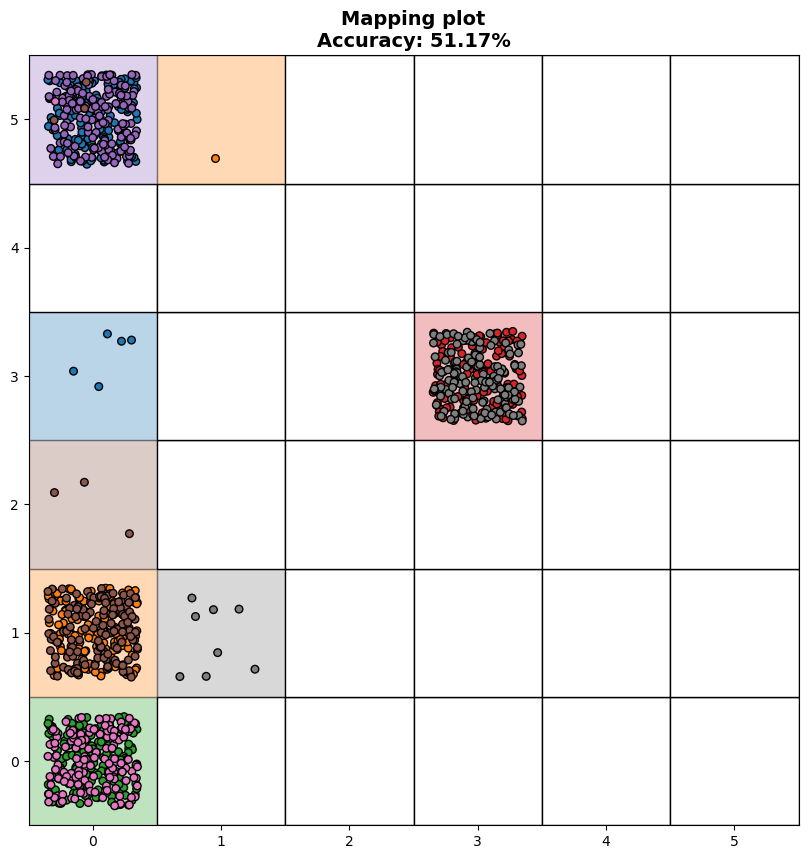

In [32]:
accuracy = mapping_plot(model, cube_data, y_etykiety)

In [33]:
model = Kohonen(10, 10, n, 100, 1, meksykanski_kapelusz, 50)
model.train(cube_data)

100%|██████████| 100/100 [00:04<00:00, 20.75it/s]


In [34]:
wykres_3d(model, cube_data, y_etykiety)

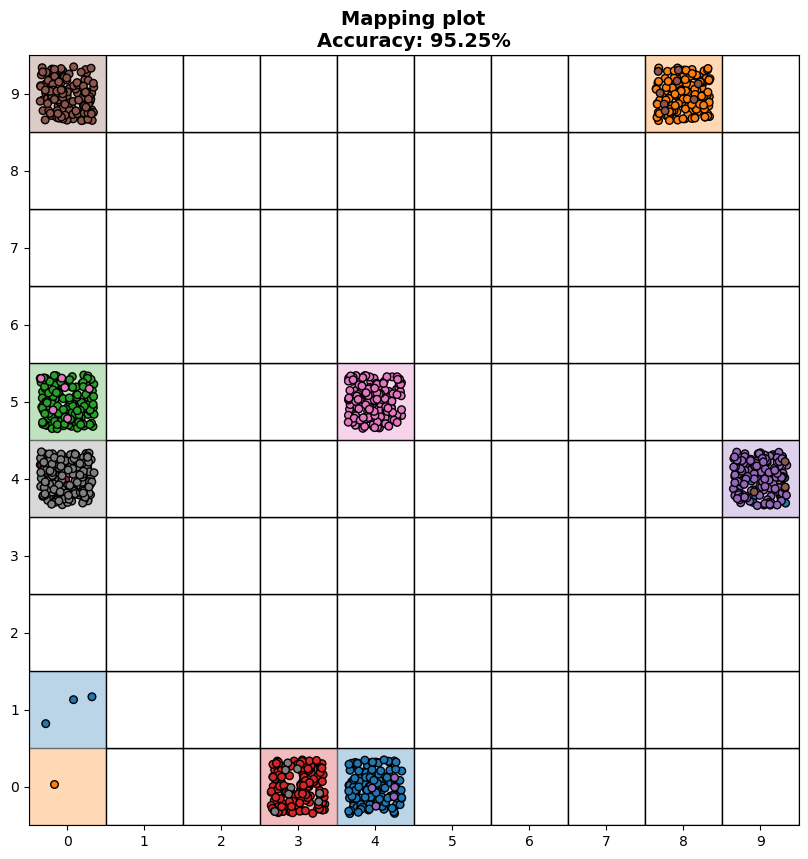

In [35]:
accuracy = mapping_plot(model, cube_data, y_etykiety)